# Simulación de trayectorias y valoración de opciones


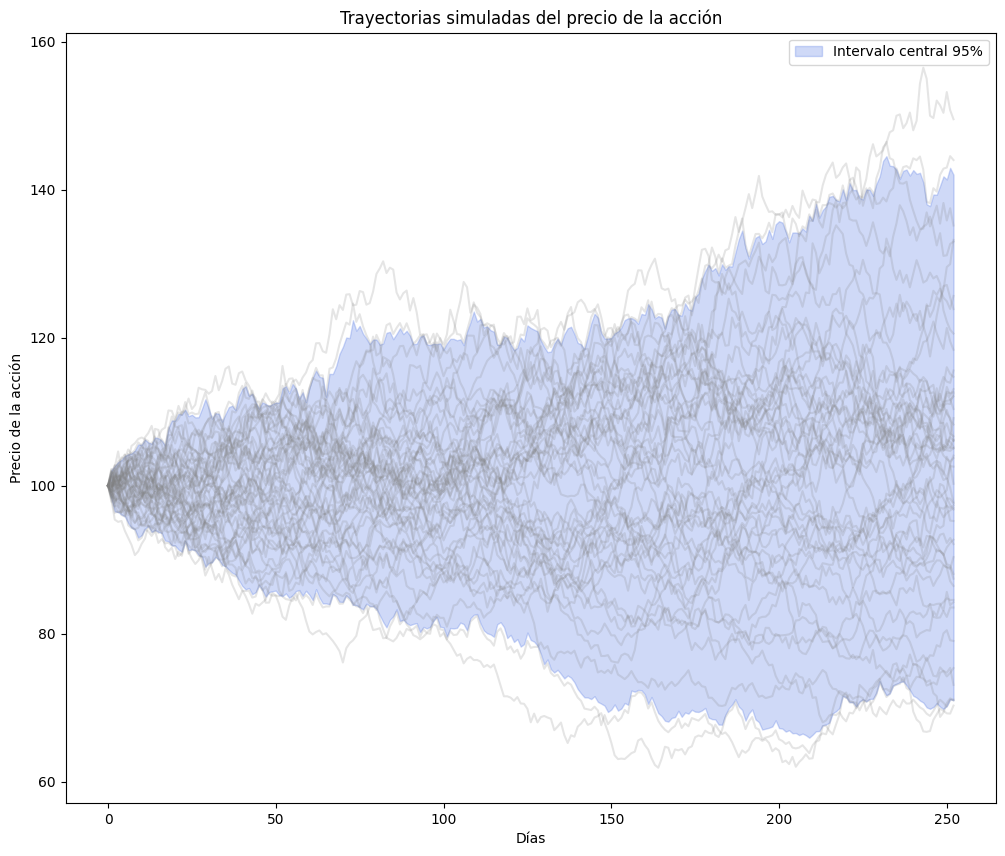

In [55]:
import numpy as np
import matplotlib.pyplot as plt

def s(r, sigma, T, S0):
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * np.random.normal(0, 1))

trayectorias = []
for i in range(50):
    trayectoria = [100]
    dt = 1/252
    T = 0
    for j in range(252):
        S0 = s(0.05, 0.20, dt, trayectoria[-1])
        trayectoria.append(S0)
    trayectorias.append(trayectoria)

trayectorias = np.array(trayectorias)

limite_inferior, limite_superior = np.percentile(trayectorias, [2.5, 97.5], axis=0)

plt.figure(figsize=(12, 10))
for i in range(trayectorias.shape[0]):
    plt.plot(dias, trayectorias[i], alpha=0.2, color='grey')
plt.fill_between(range(253), limite_inferior, limite_superior, color='royalblue', alpha=0.25, label='Intervalo central 95%')
plt.title('Trayectorias simuladas del precio de la acción')
plt.xlabel('Días')
plt.ylabel('Precio de la acción')
plt.legend()
plt.show()

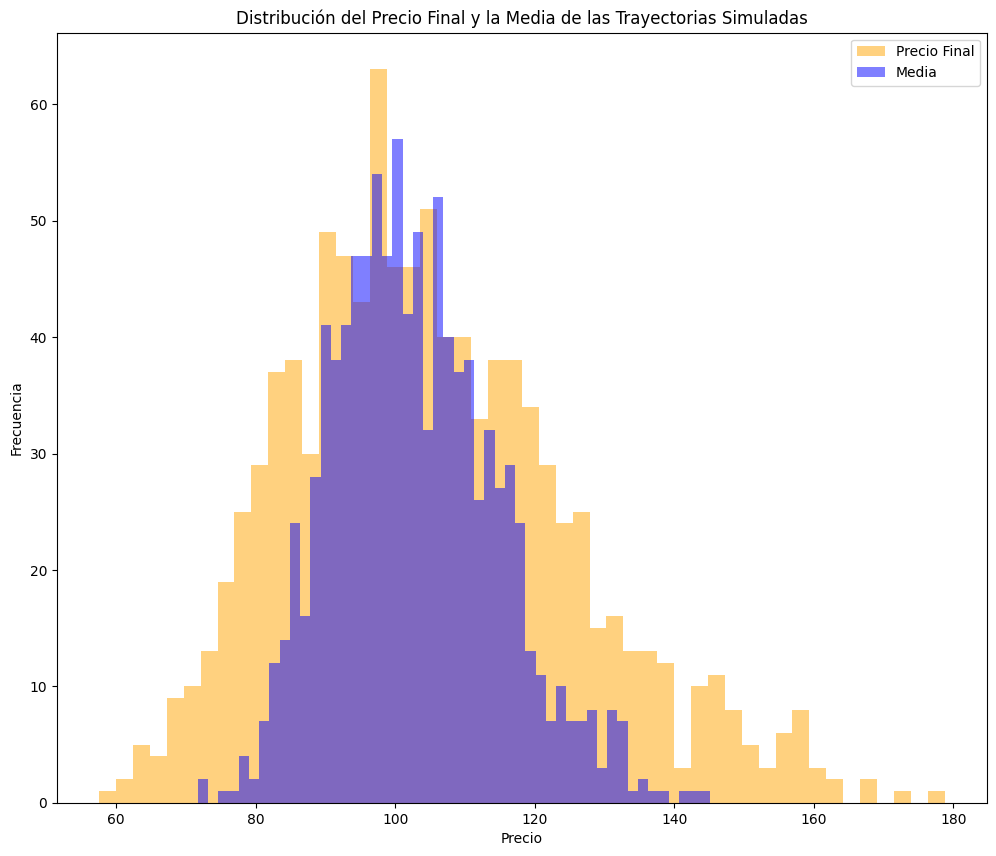

In [56]:
trayectorias = []
Media = []
Precio_Final = []
for i in range(1000):
    trayectoria = [100]
    dt = 1/252
    T = 0
    for j in range(252):
        S0 = s(0.05, 0.20, dt, trayectoria[-1])
        trayectoria.append(S0)
    trayectorias.append(trayectoria)
    Media.append(np.mean(trayectoria[1:]))
    Precio_Final.append(trayectoria[-1])

plt.figure(figsize=(12, 10))
plt.hist(Precio_Final, bins=50, alpha=0.5, label='Precio Final', color='orange')
plt.hist(Media, bins=50, color='blue', alpha=0.5, label='Media')
plt.xlabel('Precio')
plt.ylabel('Frecuencia')
plt.title('Distribución del Precio Final y la Media de las Trayectorias Simuladas')
plt.legend()
plt.show()

Media = np.array(Media)
Precio_Final = np.array(Precio_Final)

In [57]:
payoff_eu = np.maximum(Precio_Final - 110, 0)
payoff_as = np.maximum(Media - 110, 0)

mean_payoff_eu = np.mean(payoff_eu)
mean_payoff_as = np.mean(payoff_as)

VP_payoff_eu = mean_payoff_eu * np.exp(-0.05 * 1)
VP_payoff_as = mean_payoff_as * np.exp(-0.05 * 1)

print(f'Ganancia promedio de la opción europea: {VP_payoff_eu:.2f}')
print(f'Ganancia promedio de la opción asiática: {VP_payoff_as:.2f}')

Ganancia promedio de la opción europea: 5.89
Ganancia promedio de la opción asiática: 2.04


In [58]:
vol_payoff_eu = np.std(payoff_eu)
vol_payoff_as = np.std(payoff_as)

print(f'Volatilidad de la opción europea: {vol_payoff_eu:.2f}')
print(f'Volatilidad de la opción asiática: {vol_payoff_as:.2f}')

Volatilidad de la opción europea: 11.67
Volatilidad de la opción asiática: 5.09
